In [1]:
import functions as AvT
import xarray as xr
import numpy as np
import mne
from datetime import datetime
import os
import math

Optional: load events

In [8]:
directory_name = "labelled_data_200hz.nc speed n_trials=9399 baseline=(None, -0.15) steps=30 2026-09-02"

In [9]:
tfr_events = []

for f in os.scandir(f"output/{directory_name}/tfr"):
    if f.name.startswith("event"):
        tfr_events.append((mne.time_frequency.read_tfrs(f.path), f.name.split("_")[1]))
    if f.name.startswith("total"):
        tfr = mne.time_frequency.read_tfrs(f.path)

Reading c:\Users\arian\Documents\Msc Artificial Intelligence\Thesis\Model\Van Tilburg\output\labelled_data_200hz.nc speed n_trials=9399 baseline=(None, -0.15) steps=30 2026-09-02\tfr\event_decision_tfr.hdf5 ...
Reading c:\Users\arian\Documents\Msc Artificial Intelligence\Thesis\Model\Van Tilburg\output\labelled_data_200hz.nc speed n_trials=9399 baseline=(None, -0.15) steps=30 2026-09-02\tfr\event_encoding_tfr.hdf5 ...
Reading c:\Users\arian\Documents\Msc Artificial Intelligence\Thesis\Model\Van Tilburg\output\labelled_data_200hz.nc speed n_trials=9399 baseline=(None, -0.15) steps=30 2026-09-02\tfr\event_response_tfr.hdf5 ...
Reading c:\Users\arian\Documents\Msc Artificial Intelligence\Thesis\Model\Van Tilburg\output\labelled_data_200hz.nc speed n_trials=9399 baseline=(None, -0.15) steps=30 2026-09-02\tfr\total_tfr.hdf5 ...


In [ ]:
itc_events = []

for f in os.scandir(f"output/{directory_name}/itc"):
    if f.name.startswith("event"):
        itc_events.append((mne.time_frequency.read_tfrs(f.path), f.name.split("_")[1]))
    if f.name.startswith("total"):
        itc = mne.time_frequency.read_tfrs(f.path)

1. Collecting data

In [2]:
#parameters
ds_name = "labelled_data_200hz.nc"      #file name for the dataset
condition = "speed"                     #condition
force = "high"                          #force
info_fname = "S1_epo.fif"

#create datasets
ds = xr.open_dataset(f"data/{ds_name}")
ds = ds.where(ds["condition"] == condition, drop=True)
ds = ds.where(ds["force"] == force, drop=True)
sfreq = ds.attrs['sfreq']

#create probabilities array
probs_shape = ds.probabilities.values.shape
probs = ds.probabilities.values.reshape(-1, probs_shape[2], probs_shape[3]) 

#create eeg array
eeg_shape = ds.data.values.shape
eeg = ds.data.values.reshape(-1, eeg_shape[2], eeg_shape[3])

#info object
info = mne.io.read_info(f"data/{info_fname}")
old_info = info.copy()

info = mne.create_info(
    ch_names=ds.channel.values.tolist(),
    sfreq=ds.attrs["sfreq"],
    ch_types="eeg",
)
with info._unlock():
    info["lowpass"] = float(ds.attrs["lowpass"])
    info["highpass"] = float(ds.attrs["highpass"])

montage = old_info.get_montage()
if montage is not None:
    info.set_montage(montage)

del ds #delete dataset to save memory

2. Preparing epochs

In [3]:
#parameters
n_trials = 10000                                #n_trials for the TFR
batch_size = 500                                #batch size for the processing of the TFRs

#filter valid trials
valid_trials = ~np.isnan(eeg[:, :, 0]).any(axis=1)
n_valid_trials = eeg[valid_trials].shape[0]
if n_valid_trials < n_trials:
    n_trials = n_valid_trials
    print(f"There are not enough valid trials to complete your request, we changed the number of trials to {n_valid_trials}") 

#prepare epochs
batches = []

for batch in range(math.ceil(n_trials/batch_size)):
    lower = batch*batch_size
    upper = batch*batch_size+min(batch_size, n_trials-batch_size*batch)
    batches.append((eeg[valid_trials][lower:upper, :, :], probs[valid_trials][lower:upper, :, :]))

#create epochs
epochs_batches = []

for eeg_batch, probs_batch in batches:
    epochs_batches.append((mne.EpochsArray(np.nan_to_num(eeg_batch, nan=0.0), info, tmin=-0.2), probs_batch))

There are not enough valid trials to complete your request, we changed the number of trials to 9399
Not setting metadata
500 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
500 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
500 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
500 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
500 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
500 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
500 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
500 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
500 matching events fou

3. Generating events

In [4]:
#parameters
n_jobs = 1                                                              #parallel processes
baseline = (None, -0.15)                                                #TFR baseline       
steps = 30                                                              #n_steps within the frequency interval
save = True                                                             #True if TFR are saved to .hdf5 files

low_freq = 2                                                            #lower bound frequency interval
high_freq = 40                                                          #higher bound frequency interval

low_cycle = 3                                                           #lower bound n_cycle interval
high_cycle = 8                                                          #higher bound n_cycle interval

log = False                                                             #will output the proces if true

labels = ['null', 'encoding', 'decision', 'confirmation', 'response']

freqs = list(np.logspace(np.log10(low_freq), np.log10(high_freq), steps))
n_cycles = list(np.logspace(np.log10(low_cycle), np.log10(high_cycle), steps))

if save:
    directory_name = f"output/{ds_name} {condition} n_trials={n_trials} baseline={baseline} steps={steps} {datetime.today().strftime('%Y-%m-%d')}"
    if not os.path.exists(directory_name):
        os.mkdir(directory_name)
    


3.1 Generating TFR events

In [ ]:
#per epoch batch create a TFR and TFR events
for n, (epochs_batch, probs_batch) in enumerate(epochs_batches):
    print(f"batch: {n+1}/{len(epochs_batches)}")
    if n == 0:
        #create TFR and TFR events
        tfr = AvT.get_tfr(epochs_batch, freqs, baseline, jobs=n_jobs, cycles=n_cycles)
        tfr_events = AvT.get_events(tfr, probs_batch, freqs, info, labels, baseline=baseline, instance='tfr', cycles=n_cycles, jobs=n_jobs, log=log)
        total_tfr = tfr.average()
    else:
        temp_tfr = AvT.get_tfr(epochs_batch, freqs, baseline, jobs=n_jobs, cycles=n_cycles)
        temp_tfr_events = AvT.get_events(temp_tfr, probs_batch, freqs, info, labels, baseline=baseline, instance='tfr', cycles=n_cycles, jobs=n_jobs, log=log)
        temp_tfr = temp_tfr.average()  

        #add TFR and TFR events to current instances
        for n, temp_tfr_event in enumerate(temp_tfr_events):
                    tfr_events[n].__add__(temp_tfr_event)
        total_tfr.__add__(temp_tfr)
        
        del temp_tfr
        del temp_tfr_events

#divide TFR and TFR events by the amount of batches
total_tfr._data/(n_trials/batch_size)
total_tfr._data[total_tfr._data == -np.inf] = np.nan
tfr = total_tfr
for (tfr_event, _) in tfr_events:
    tfr_event._data/(n_trials/batch_size)

del total_tfr
del epochs_batches

#save TFR
if save:
    os.mkdir(f"{directory_name}/tfr")
    total_tfr.save(f"{directory_name}/tfr/total_tfr.hdf5", overwrite=True)

    for n, (tfr_event, label) in enumerate(tfr_events):
        tfr_event.save(f"{directory_name}/tfr/event_{label}_tfr.hdf5", overwrite=True)

batch: 1/19
Applying baseline correction (mode: logratio)


C:\Users\arian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\mne\baseline.py:115: RuntimeWarning: divide by zero encountered in log10
  np.log10(d, out=d)


batch: 2/19
Applying baseline correction (mode: logratio)


C:\Users\arian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\mne\baseline.py:115: RuntimeWarning: divide by zero encountered in log10
  np.log10(d, out=d)


batch: 3/19
Applying baseline correction (mode: logratio)


...

C:\Users\arian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\mne\baseline.py:115: RuntimeWarning: divide by zero encountered in log10
  np.log10(d, out=d)


batch: 18/19
Applying baseline correction (mode: logratio)


C:\Users\arian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\mne\baseline.py:115: RuntimeWarning: divide by zero encountered in log10
  np.log10(d, out=d)


batch: 19/19
Applying baseline correction (mode: logratio)


C:\Users\arian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\mne\baseline.py:115: RuntimeWarning: divide by zero encountered in log10
  np.log10(d, out=d)


3.2 Generating ITC events

In [ ]:
#create ITC and ITC events
epochs = mne.EpochsArray(np.nan_to_num(eeg[valid_trials][:n_trials, :, :], nan=0.0), info, tmin=-0.2)

del eeg

itc = AvT.get_itc(epochs, freqs, jobs=n_jobs, cycles=n_cycles)
itc_events = AvT.get_events(epochs, probs[valid_trials][:n_trials, :, :], freqs, info, labels, jobs=n_jobs, cycles=n_cycles, log=log, instance='itc')

#save ITC
if save:
    os.mkdir(f"{directory_name}/itc")

    itc.save(f"{directory_name}/itc/total_itc.hdf5", overwrite=True)

    for n, (itc_event, label) in enumerate(itc_events):
        itc_event.save(f"{directory_name}/itc/event_{label}_itc.hdf5", overwrite=True)

Not setting metadata
9399 matching events found
No baseline correction applied
0 projection items activated


C:\Users\arian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\mne\time_frequency\tfr.py:750: RuntimeWarning: invalid value encountered in divide
  plf += tfr / tfr_abs  # phase


Not setting metadata9
9399 matching events found
No baseline correction applied
0 projection items activated


C:\Users\arian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\mne\time_frequency\tfr.py:750: RuntimeWarning: invalid value encountered in divide
  plf += tfr / tfr_abs  # phase


Not setting metadata9
9399 matching events found
No baseline correction applied
0 projection items activated


C:\Users\arian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\mne\time_frequency\tfr.py:750: RuntimeWarning: invalid value encountered in divide
  plf += tfr / tfr_abs  # phase


Not setting metadata9
9399 matching events found
No baseline correction applied
0 projection items activated


C:\Users\arian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\mne\time_frequency\tfr.py:750: RuntimeWarning: invalid value encountered in divide
  plf += tfr / tfr_abs  # phase


4. Plot TFR events

No baseline correction applied
No baseline correction applied
No baseline correction applied
No baseline correction applied
No baseline correction applied
No baseline correction applied
No baseline correction applied
No baseline correction applied
No baseline correction applied
No baseline correction applied


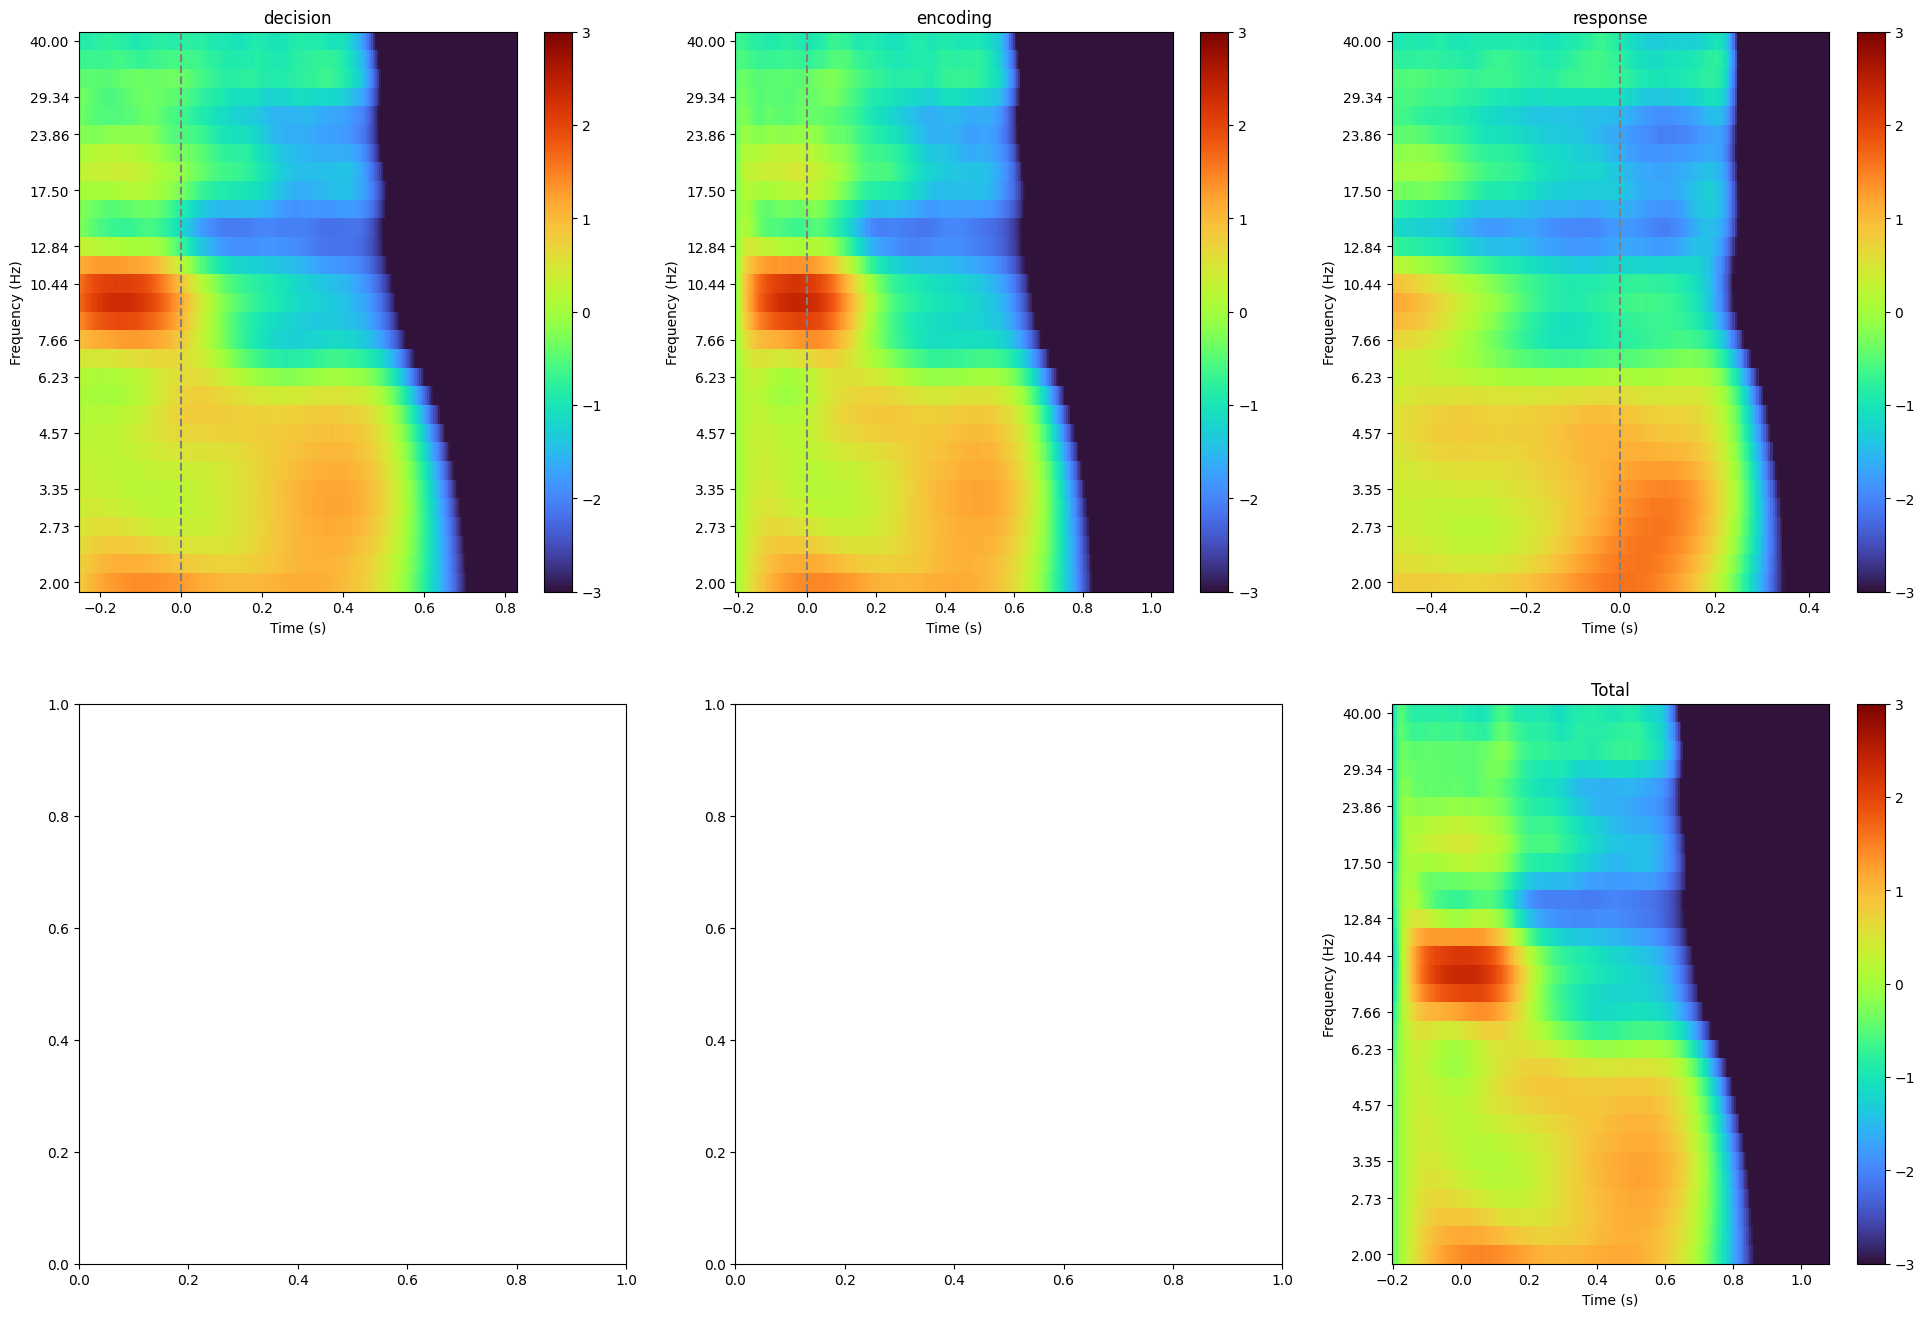

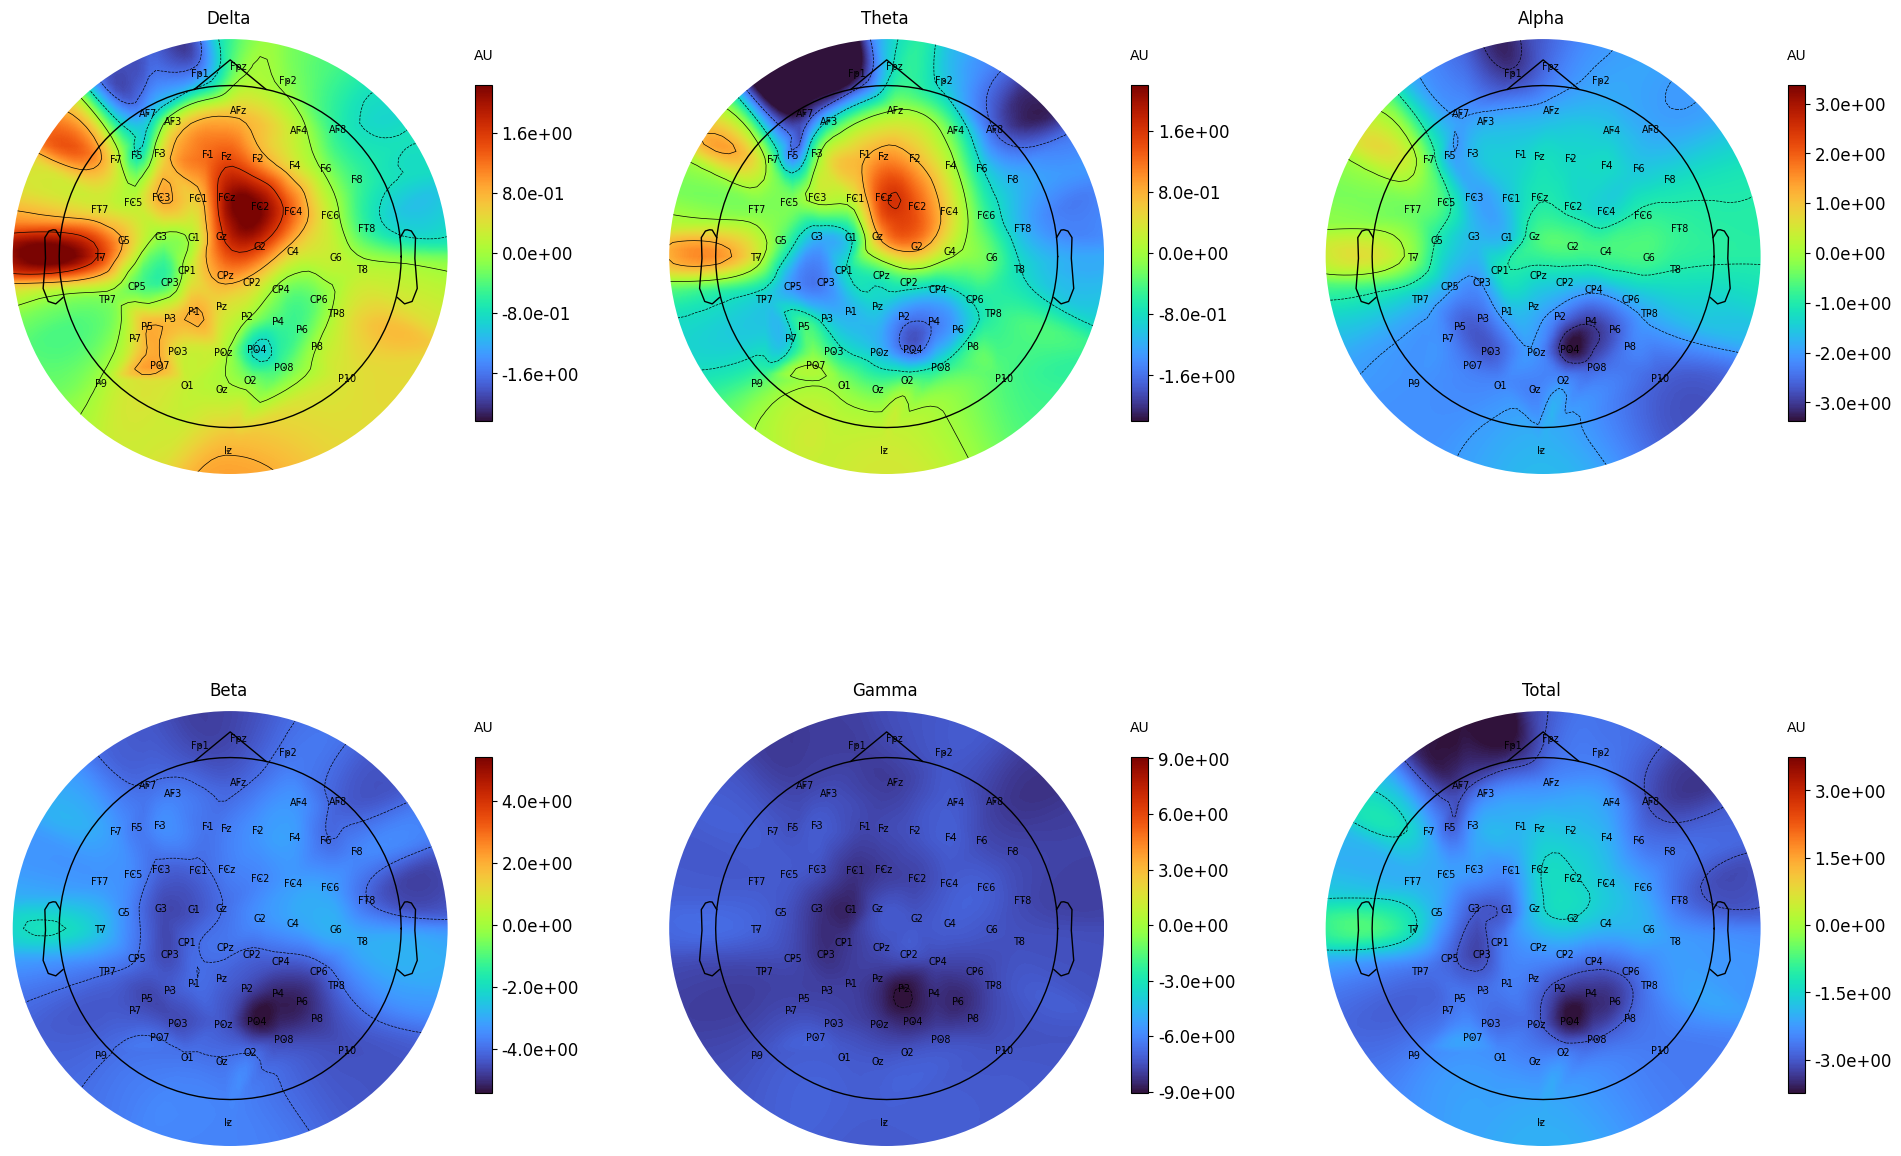

No baseline correction applied
No baseline correction applied
No baseline correction applied
No baseline correction applied
No baseline correction applied
No baseline correction applied
No baseline correction applied
No baseline correction applied
No baseline correction applied
No baseline correction applied


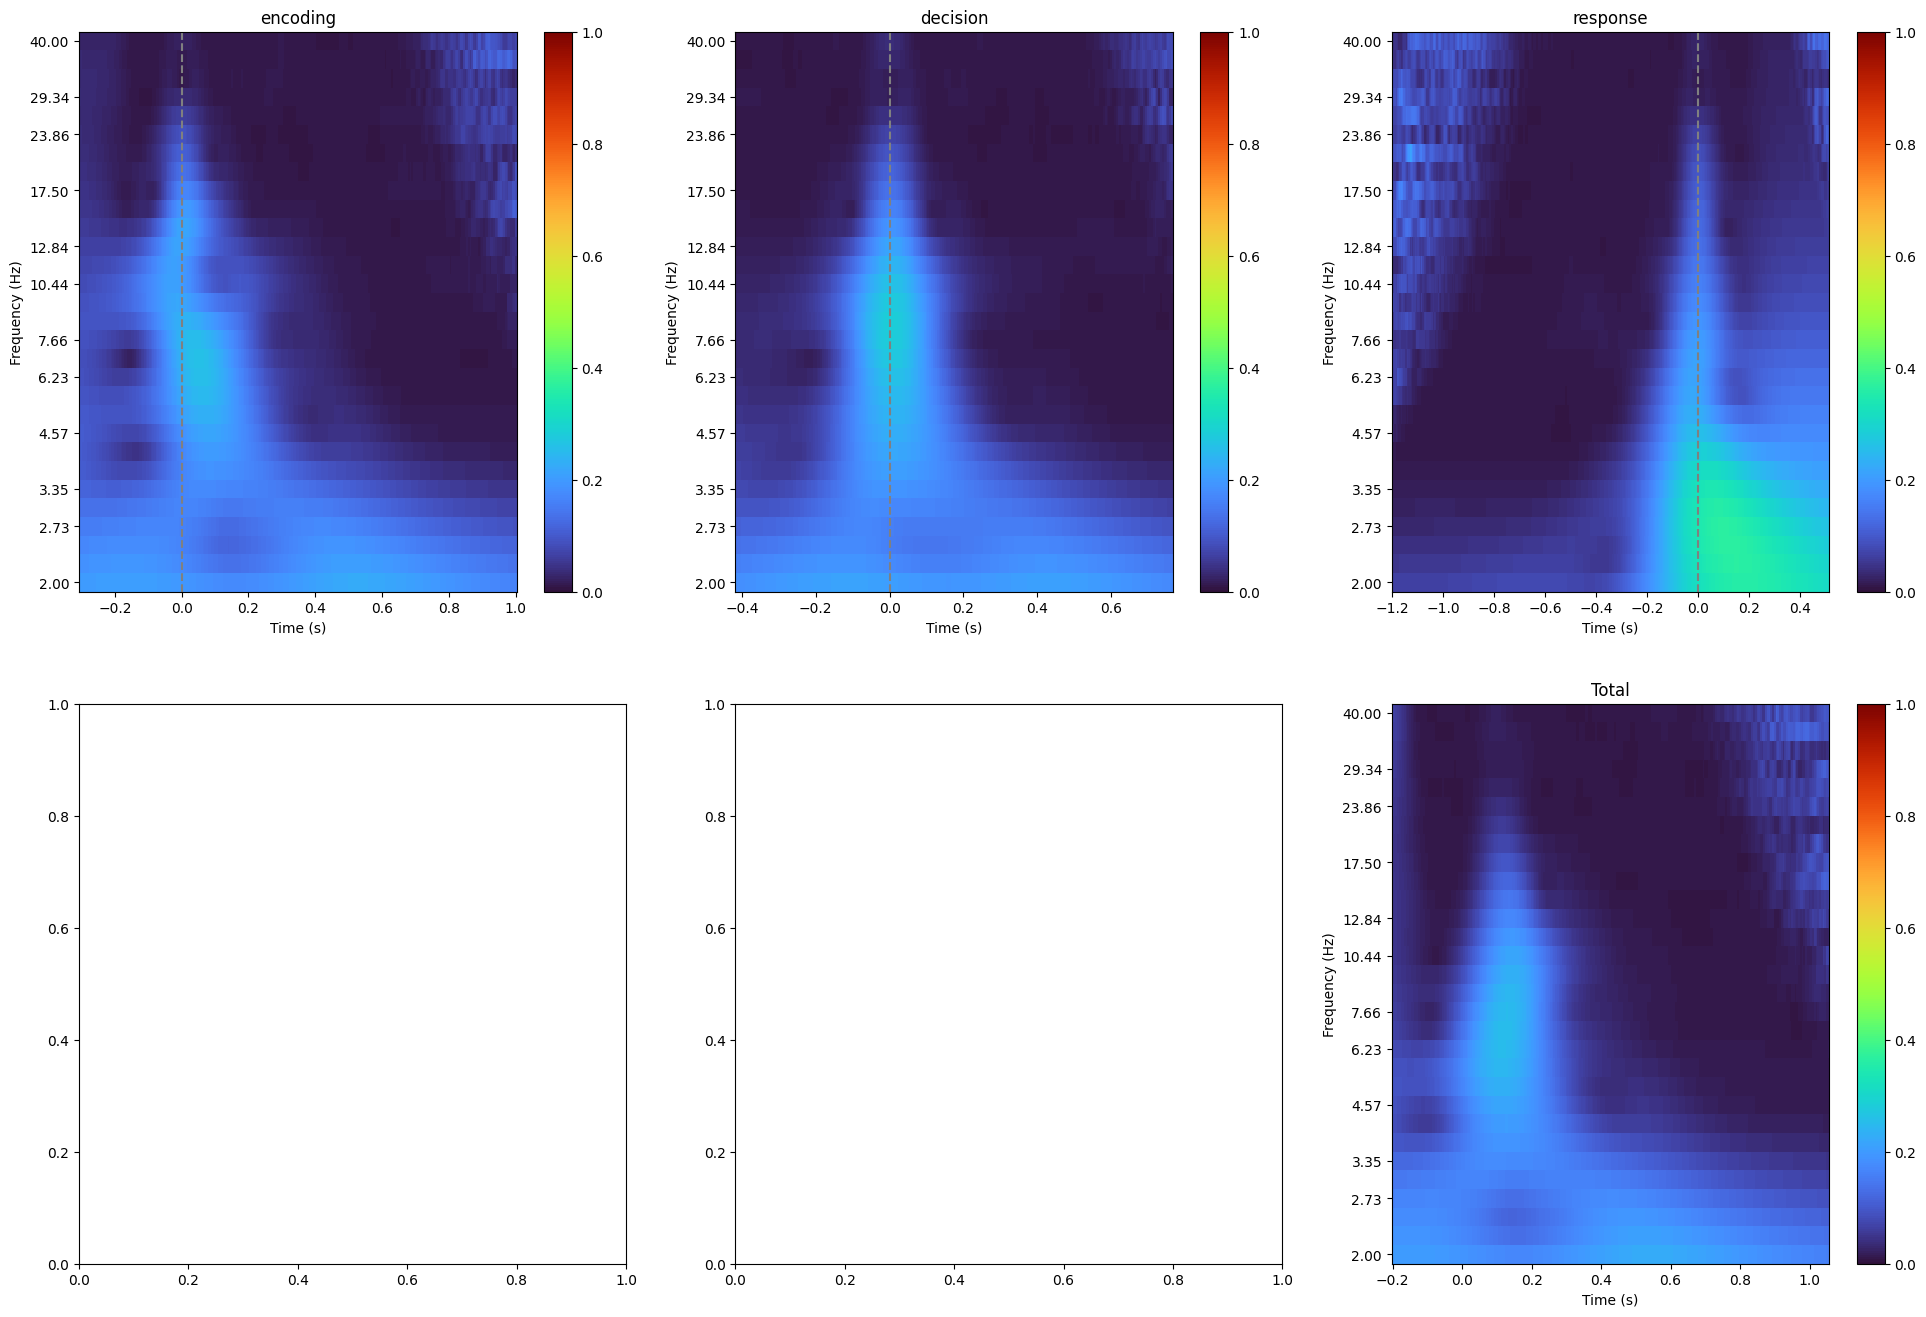

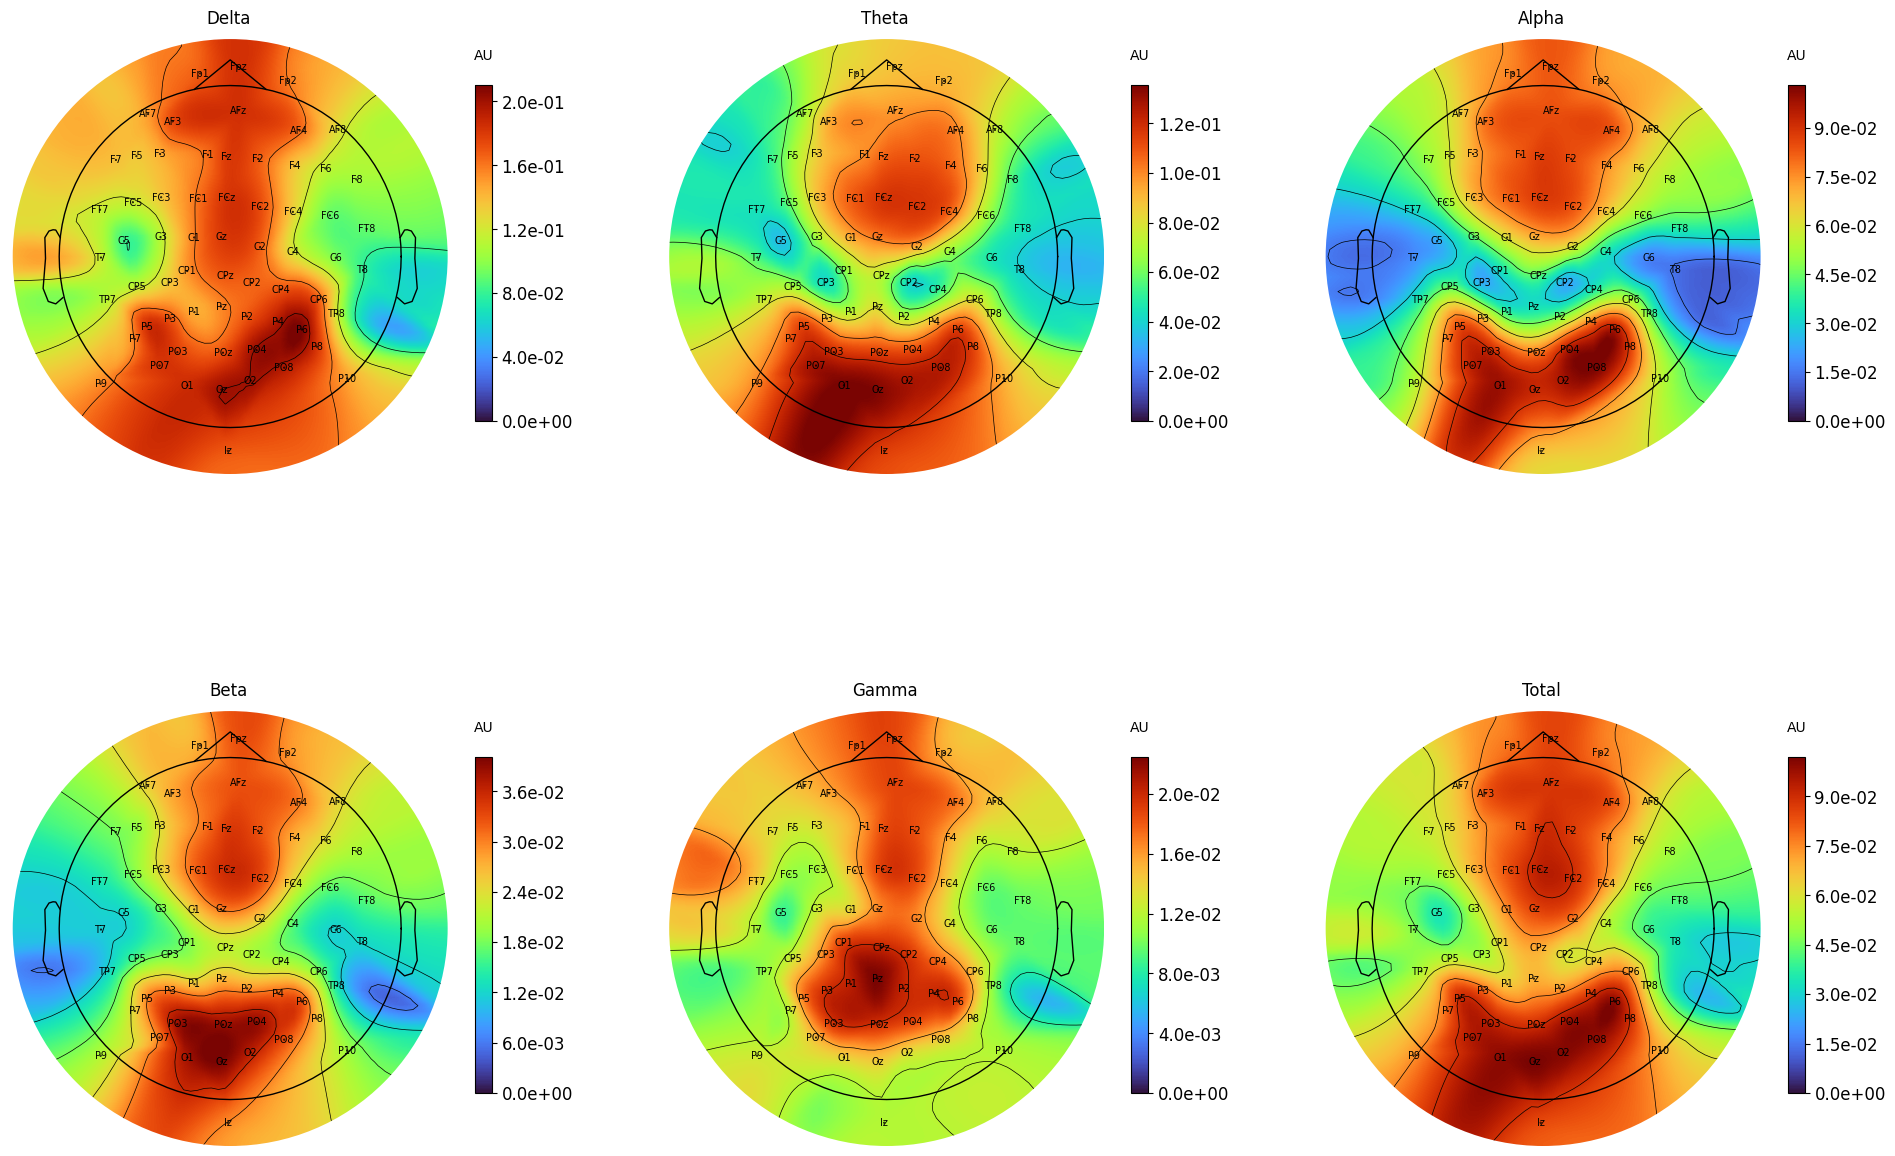

In [10]:
#parameters
channels = ['all']                                                                          #channels to be plotted                                                                          #power
x_axis = 'adaptive'                                                                        #frequency (Hz)

AvT.plot_events(tfr, tfr_events, channels, instance='tfr', x_axis=x_axis)
AvT.plot_events(itc, itc_events, channels, instance='itc', x_axis=x_axis)